# Well-Log Lithology Classifier - Notebook

**Course:** Machine Learning Zoomcamp (2026 Cohort)  
**Author:** Wisnu Anugrah Pratama  
**GitHub:** [@wapratama](https://github.com/wapratama)

---

### Overview
This notebook contains my technical write-up for **Midterm Project** as part of the [Machine Learning Zoomcamp](https://github.com/DataTalksClub/machine-learning-zoomcamp) by DataTalksClub.

**Problem:** Predict the lithology (rock type) at every depth sample of a well from wireline logs, so a geoscientist gets a fast first-pass interpretation on a *new* well.

**Dataset:** FORCE 2020 lithology competition dataset (Norwegian Sea): 98 labelled training wells, plus two blind sets of 10 wells each (leaderboard + hidden test). Bormann et al. (2020), DOI 10.5281/zenodo.4351156. Dataset licence CC BY 4.0; original logs from the Norwegian government under NOLD 2.0.

**Key Design Decisions:**
1. **Validation is grouped by well** (`StratifiedGroupKFold`). Neighbouring depth samples (0.152 m apart) are almost duplicates, so a random row split would leak and inflate scores.
2. **Metric.** The competition's asymmetric *penalty score* (0 = perfect, more negative = worse) is the primary metric; macro-F1, balanced accuracy and accuracy are reported alongside because the classes are heavily imbalanced.
3. **Held-out wells** (`hidden_test`, `leaderboard_test`) are touched only once, at the end.

**Notebook Map:**

| Section | Section Content | Rubric Criterion |
|---|---|---|
| 1-6 | Load, target, missing data, cleaning, EDA, feature engineering | EDA, data preparation |
| 7-8 | Validation design, ablation and feature importance | EDA (feature importance) |
| 9-10 | Model comparison and hyper-parameter tuning | Model training (linear + tree-based, tuned) |
| 11-12 | Held-out evaluation and artefacts | Model selection, hand-off to `train.py` | 

**Important Note:** Open this `notebook.ipynb` from the project root so `import lithology` works. Run: `uv run jupyter lab`.

## 1. Setup and experiment settings

In [1]:
from __future__ import annotations

import json
import time
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, make_scorer,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer

from lithology.config import (
    ALL_LOGS, CLASS_COLORS, CLASS_NAMES, CODE_TO_CLASS, CODE_TO_NAME, CONFIDENCE_COL,
    DEPTH_COL, N_CLASSES, RAW_FEATURE_LOGS, SENTINEL_MAX, SPARSE_LOGS, TARGET_COL, WELL_COL,
)
from lithology.features import FEATURE_SETS, LOG10_FEATURES, add_features, clean_logs
from lithology.metrics import load_penalty_matrix, make_penalty_scorer, penalty_score

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
RAW, MODELS = Path("data/raw"), Path("models")
MODELS.mkdir(exist_ok=True)

In [2]:
# --- Experiment settings -------------------------------------------------------------
# Samples are 0.152 m apart and strongly autocorrelated, so experiments use every k-th
# sample per well ("thinning"). Smaller stride = more rows = slower but slightly better.
STRIDE_DEV = 15        # dev set for ablation, model comparison and tuning (~78k rows)
STRIDE_FINAL = 5       # training set for the final fit before the blind-well evaluation
N_SPLITS = 5
N_ITER_LR, N_ITER_RF, N_ITER_LGBM = 4, 6, 12
RF_TREES = 150
ABLATION_TREES = 150

## 2. Load the data

In [3]:
t0 = time.time()
train_raw = pd.read_csv(RAW / "train.csv", sep=";")
print(f"{len(train_raw):,} rows x {train_raw.shape[1]} columns | {train_raw[WELL_COL].nunique()} wells | loaded in {time.time() - t0:.1f}s")
train_raw.head()

1,170,511 rows x 29 columns | 98 wells | loaded in 3.4s


,WELL,DEPTH_MD,X_LOC,Y_LOC,Z_LOC,GROUP,FORMATION,CALI,RSHA,RMED,...,ROP,DTS,DCAL,DRHO,MUDWEIGHT,RMIC,ROPA,RXO,FORCE_2020_LITHOFACIES_LITHOLOGY,FORCE_2020_LITHOFACIES_CONFIDENCE
0,15/9-13,494.528,437641.96875,6470972.5,-469.501831,NORDLAND GP.,NaN,19.480835,NaN,1.611410,...,34.636410,NaN,NaN,-0.574928,NaN,NaN,NaN,NaN,65000,1.0
1,15/9-13,494.680,437641.96875,6470972.5,-469.653809,NORDLAND GP.,NaN,19.468800,NaN,1.618070,...,34.636410,NaN,NaN,-0.570188,NaN,NaN,NaN,NaN,65000,1.0
2,15/9-13,494.832,437641.96875,6470972.5,-469.805786,NORDLAND GP.,NaN,19.468800,NaN,1.626459,...,34.779556,NaN,NaN,-0.574245,NaN,NaN,NaN,NaN,65000,1.0
3,15/9-13,494.984,437641.96875,6470972.5,-469.957794,NORDLAND GP.,NaN,19.459282,NaN,1.621594,...,39.965164,NaN,NaN,-0.586315,NaN,NaN,NaN,NaN,65000,1.0
4,15/9-13,495.136,437641.96875,6470972.5,-470.109772,NORDLAND GP.,NaN,19.453100,NaN,1.602679,...,57.483765,NaN,NaN,-0.597914,NaN,NaN,NaN,NaN,65000,1.0


In [4]:
train_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1170511 entries, 0 to 1170510
Data columns (total 29 columns):
 #   Column                             Non-Null Count    Dtype  
---  ------                             --------------    -----  
 0   WELL                               1170511 non-null  str    
 1   DEPTH_MD                           1170511 non-null  float64
 2   X_LOC                              1159736 non-null  float64
 3   Y_LOC                              1159736 non-null  float64
 4   Z_LOC                              1159736 non-null  float64
 5   GROUP                              1169233 non-null  str    
 6   FORMATION                          1033517 non-null  str    
 7   CALI                               1082634 non-null  float64
 8   RSHA                               630650 non-null   float64
 9   RMED                               1131518 non-null  float64
 10  RDEP                               1159496 non-null  float64
 11  RHOB                               

In [5]:
per_well = train_raw.groupby(WELL_COL)[DEPTH_COL].agg(n_samples="size", top_m="min", base_m="max")
per_well["step_m"] = (per_well.base_m - per_well.top_m) / (per_well.n_samples - 1)
display(per_well.describe().round(3))
print("Sorted by depth inside every well:",
      bool(train_raw.groupby(WELL_COL)[DEPTH_COL].apply(lambda s: s.is_monotonic_increasing).all()))

,n_samples,top_m,base_m,step_m
count,98.000,98.000,98.000,98.000
mean,11943.990,1384.819,3213.126,0.153
std,6722.213,1074.568,864.665,0.003
min,1734.000,136.086,1294.108,0.152
25%,5544.250,539.562,2537.261,0.152
50%,12534.000,1028.656,3172.520,0.152
75%,17332.000,1920.212,3891.338,0.153
max,25131.000,4360.016,5436.632,0.173


Sorted by depth inside every well: True


In [6]:
hidden = pd.read_csv(RAW / "hidden_test.csv", sep=";")
lb_features = pd.read_csv(RAW / "leaderboard_test_features.csv", sep=";")
lb_target = pd.read_csv(RAW / "leaderboard_test_target.csv", sep=";")
assert (lb_features[WELL_COL].to_numpy() == lb_target[WELL_COL].to_numpy()).all()
assert np.allclose(lb_features[DEPTH_COL], lb_target[DEPTH_COL])
leaderboard = lb_features.assign(**{TARGET_COL: lb_target[TARGET_COL].to_numpy()})

train_wells, hidden_wells, lb_wells = set(train_raw[WELL_COL]), set(hidden[WELL_COL]), set(leaderboard[WELL_COL])
assert not (train_wells & hidden_wells) and not (train_wells & lb_wells) and not (hidden_wells & lb_wells)
print(f"train: {len(train_wells)} wells | leaderboard: {len(lb_wells)} wells, {len(leaderboard):,} rows | hidden: {len(hidden_wells)} wells, {len(hidden):,} rows")
print("No well appears in more than one split.")

train: 98 wells | leaderboard: 10 wells, 136,786 rows | hidden: 10 wells, 122,397 rows
No well appears in more than one split.


## 3. Target variable
Lithology codes are mapped to the 12 class indices used by the official penalty matrix. Two things to look at: **class imbalance** and **in how many wells each class appears**. A class that exists in only a handful of wells is the hard case for well-grouped validation.

,rows,share_%,wells_present
FORCE_2020_LITHOFACIES_LITHOLOGY,,,
Shale,720803,61.58,98
Sandstone,168937,14.43,98
Sandstone/Shale,150455,12.85,97
Limestone,56320,4.81,94
Marl,33329,2.85,73
Tuff,15245,1.30,55
Chalk,10513,0.90,11
Halite,8213,0.70,3
Coal,3820,0.33,51


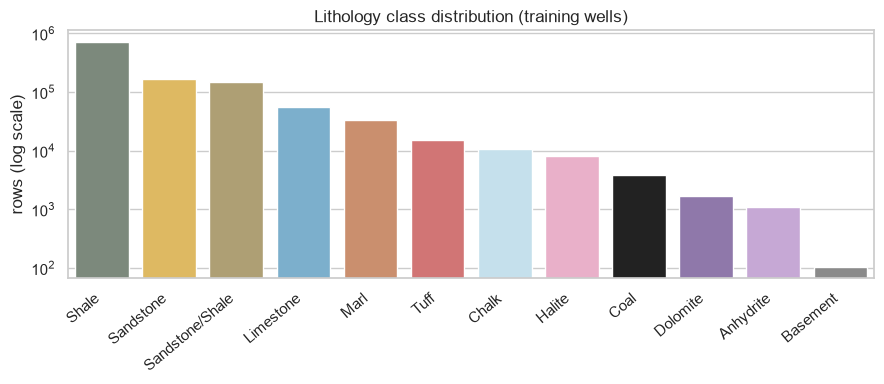

In [7]:
names = train_raw[TARGET_COL].map(CODE_TO_NAME)
target_summary = names.value_counts().rename("rows").to_frame()
target_summary["share_%"] = (100 * target_summary.rows / target_summary.rows.sum()).round(2)
target_summary["wells_present"] = train_raw.assign(name=names).groupby("name")[WELL_COL].nunique()
display(target_summary)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=target_summary.index, y=target_summary.rows, hue=target_summary.index,
            palette=dict(zip(CLASS_NAMES, CLASS_COLORS)), legend=False, ax=ax)
ax.set_yscale("log"); ax.set_ylabel("rows (log scale)"); ax.set_xlabel("")
ax.set_title("Lithology class distribution (training wells)")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

In [8]:
# The labels carry an interpreter confidence flag (1 = high, 3 = low).
print(train_raw[CONFIDENCE_COL].value_counts(dropna=False).sort_index())
print()
display(pd.crosstab(names, train_raw[CONFIDENCE_COL], normalize="index").round(3))

FORCE_2020_LITHOFACIES_CONFIDENCE
1.0    1013705
2.0     121018
3.0      35609
NaN        179
Name: count, dtype: int64



FORCE_2020_LITHOFACIES_CONFIDENCE,1.0,2.0,3.0
FORCE_2020_LITHOFACIES_LITHOLOGY,,,
Anhydrite,0.809,0.182,0.008
Basement,0.864,0.107,0.029
Chalk,0.634,0.276,0.089
Coal,0.868,0.130,0.002
Dolomite,0.661,0.225,0.115
Halite,0.507,0.465,0.028
Limestone,0.809,0.176,0.014
Marl,0.766,0.228,0.006
Sandstone,0.914,0.076,0.010


## 4. Missing values, null sentinels and cleaning
Wireline curves are often not recorded in every well, and LAS files use sentinel values such as `-999.25` for "no data". Three checks: (a) overall missingness per curve, (b) which wells have which curves, (c) sentinels hiding inside the numbers.

Sentinel values (<= -990) per curve: {'SP': 402, 'DRHO': 1, 'ROPA': 24, 'RXO': 34482}


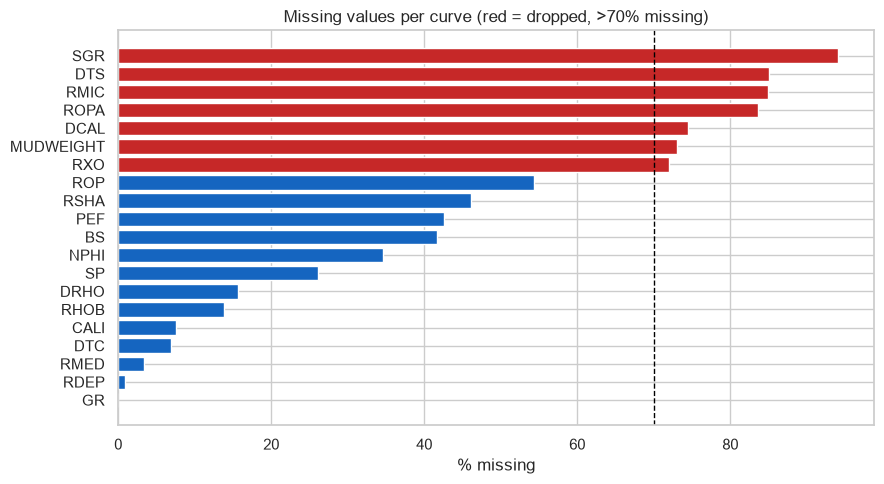

In [9]:
missing_pct = (train_raw[ALL_LOGS].isna().mean() * 100).sort_values(ascending=False)
sentinels = {c: int((train_raw[c] <= SENTINEL_MAX).sum()) for c in ALL_LOGS if (train_raw[c] <= SENTINEL_MAX).any()}
print("Sentinel values (<= -990) per curve:", sentinels)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#c62828" if c in SPARSE_LOGS else "#1565c0" for c in missing_pct.index]
ax.barh(missing_pct.index, missing_pct.values, color=colors)
ax.axvline(70, ls="--", color="black", lw=1)
ax.invert_yaxis(); ax.set_xlabel("% missing"); ax.set_title("Missing values per curve (red = dropped, >70% missing)")
plt.tight_layout(); plt.show()

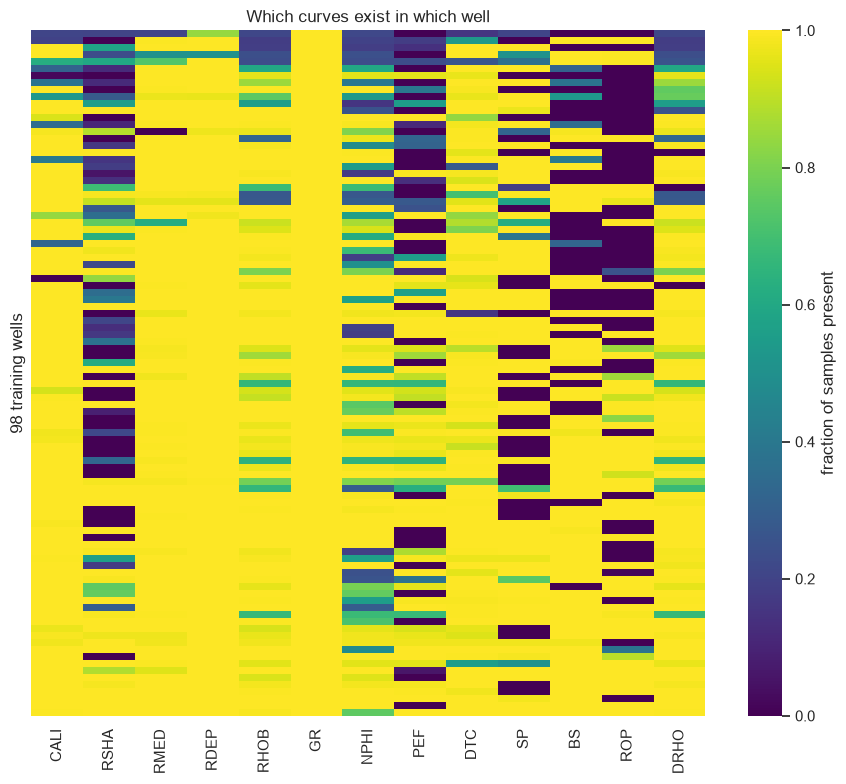

Wells with (almost) no data for a curve (<5% present):
ROP     46
SP      30
PEF     29
BS      29
RSHA    24
DRHO     3
CALI     2
RMED     1
RDEP     0
RHOB     0
DTC      0
GR       0
NPHI     0


In [10]:
usable = [c for c in ALL_LOGS if c not in SPARSE_LOGS]
availability = train_raw[usable].notna().groupby(train_raw[WELL_COL]).mean()
availability = availability.loc[availability.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(availability, cmap="viridis", yticklabels=False, cbar_kws={"label": "fraction of samples present"}, ax=ax)
ax.set_ylabel("98 training wells"); ax.set_title("Which curves exist in which well")
plt.tight_layout(); plt.show()
print("Wells with (almost) no data for a curve (<5% present):")
print((availability < 0.05).sum().sort_values(ascending=False).to_string())

**Cleaning decisions**
- Replace null sentinels (`<= -990`) with `NaN` in the curve columns only (not in coordinates, where negative values are legitimate).
- Drop the seven curves that are missing in more than ~70% of rows (`SPARSE_LOGS`); a model that depends on them could rarely be used on a new well.
- Keep the remaining gaps as `NaN`: LightGBM handles them natively, and the linear / random-forest pipelines impute them (with missing-indicator columns, since *which curves were run* is itself informative).
- Sort every well by depth so that depth-context features are valid.

In [11]:
train_clean = clean_logs(train_raw)
print("Sentinels left after cleaning:", int(sum((train_clean[c] <= SENTINEL_MAX).sum() for c in ALL_LOGS)))
ranges = train_clean[usable].describe(percentiles=[0.001, 0.5, 0.999]).T[["count", "min", "0.1%", "50%", "99.9%", "max"]]
display(ranges.round(2))

Sentinels left after cleaning: 0


,count,min,0.1%,50%,99.9%,max
CALI,1082634.0,2.34,5.99,12.56,24.95,28.28
RSHA,630650.0,0.00,0.13,1.40,1990.12,2193.90
RMED,1131518.0,-0.01,0.20,1.44,460.85,1988.62
RDEP,1159496.0,0.03,0.23,1.44,1996.34,1999.89
RHOB,1009242.0,0.72,1.34,2.32,2.91,3.46
GR,1170511.0,0.11,4.48,68.37,283.35,1076.96
NPHI,765409.0,-0.04,0.00,0.33,0.93,1.00
PEF,671692.0,0.10,0.92,4.31,163.90,383.13
DTC,1089648.0,7.42,50.10,109.59,193.24,320.48
SP,863845.0,-608.79,-250.43,55.41,511.24,526.55


## 5. Exploratory analysis: how do the logs separate lithologies?

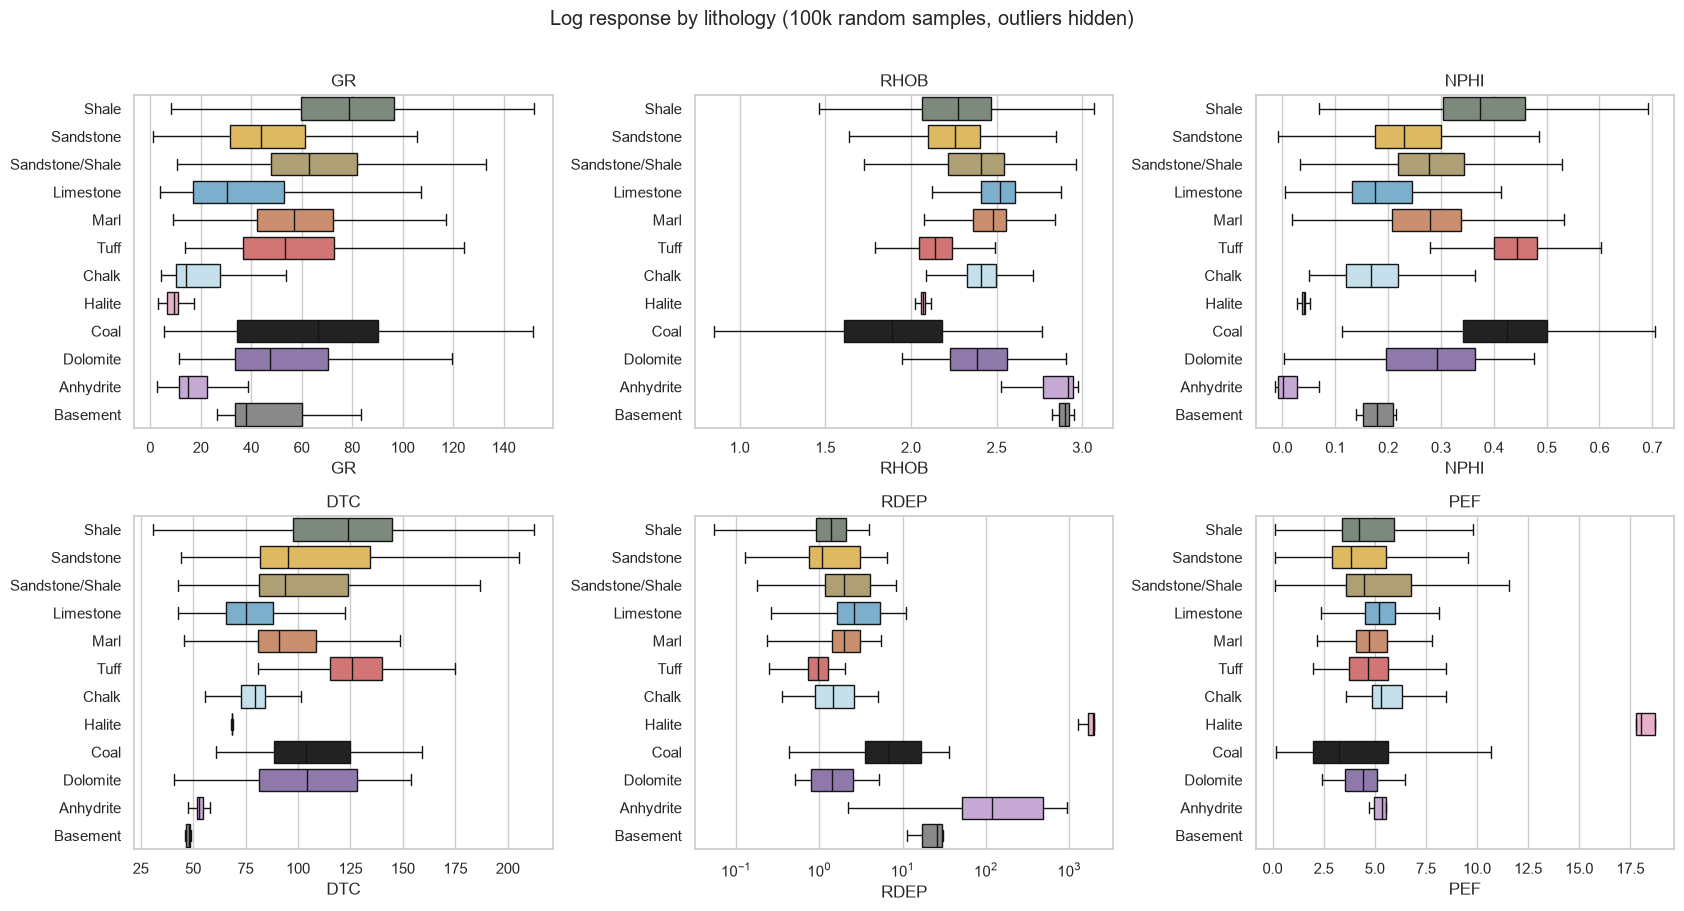

In [12]:
sample = train_clean.sample(100_000, random_state=SEED).assign(lith=lambda d: d[TARGET_COL].map(CODE_TO_NAME))
order = list(target_summary.index)
palette = dict(zip(CLASS_NAMES, CLASS_COLORS))

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (col, logx) in zip(axes.ravel(), [("GR", False), ("RHOB", False), ("NPHI", False),
                                          ("DTC", False), ("RDEP", True), ("PEF", False)]):
    sns.boxplot(data=sample, y="lith", x=col, order=order, hue="lith", palette=palette,
                legend=False, showfliers=False, ax=ax)
    if logx:
        ax.set_xscale("log")
    ax.set_ylabel(""); ax.set_title(col)
plt.suptitle("Log response by lithology (100k random samples, outliers hidden)", y=1.01)
plt.tight_layout(); plt.show()

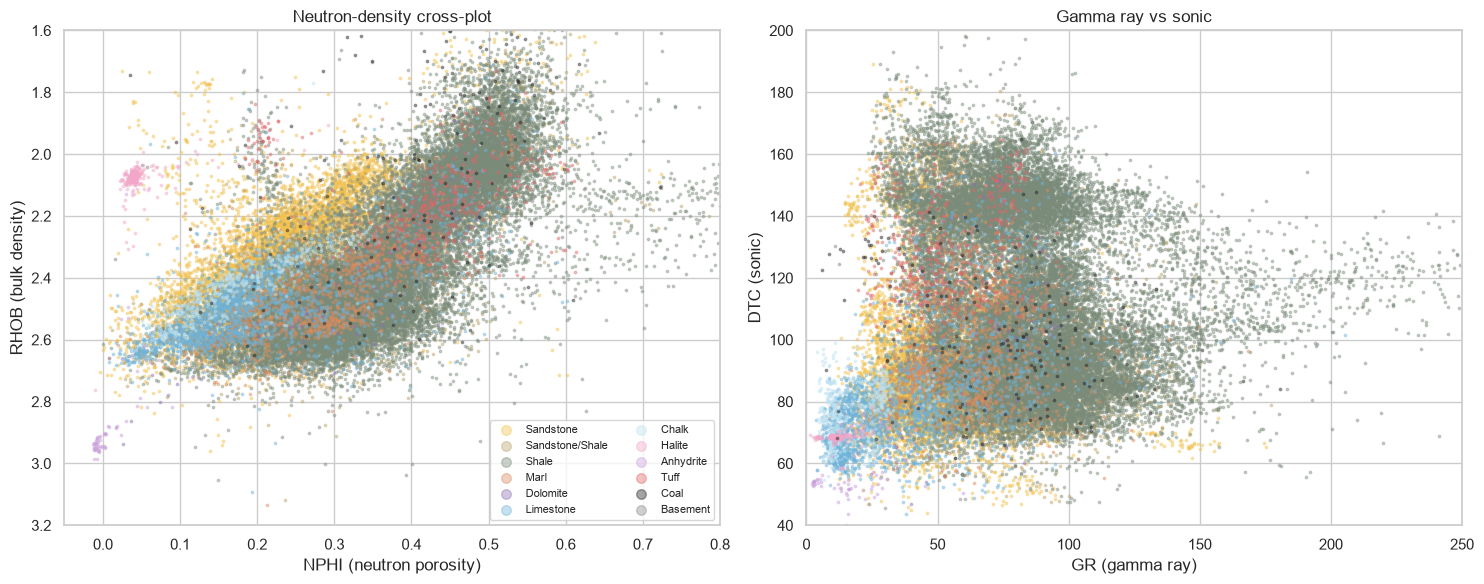

In [13]:
cp = train_clean.dropna(subset=["RHOB", "NPHI", "GR", "DTC"]).sample(40_000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for k in range(N_CLASSES):
    sub = cp[cp[TARGET_COL].map(CODE_TO_CLASS) == k]
    if len(sub):
        axes[0].scatter(sub.NPHI, sub.RHOB, s=3, alpha=0.4, color=CLASS_COLORS[k], label=CLASS_NAMES[k])
        axes[1].scatter(sub.GR, sub.DTC, s=3, alpha=0.4, color=CLASS_COLORS[k])
axes[0].set(xlim=(-0.05, 0.8), ylim=(3.2, 1.6), xlabel="NPHI (neutron porosity)", ylabel="RHOB (bulk density)", title="Neutron-density cross-plot")
axes[1].set(xlim=(0, 250), ylim=(40, 200), xlabel="GR (gamma ray)", ylabel="DTC (sonic)", title="Gamma ray vs sonic")
axes[0].legend(markerscale=4, fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

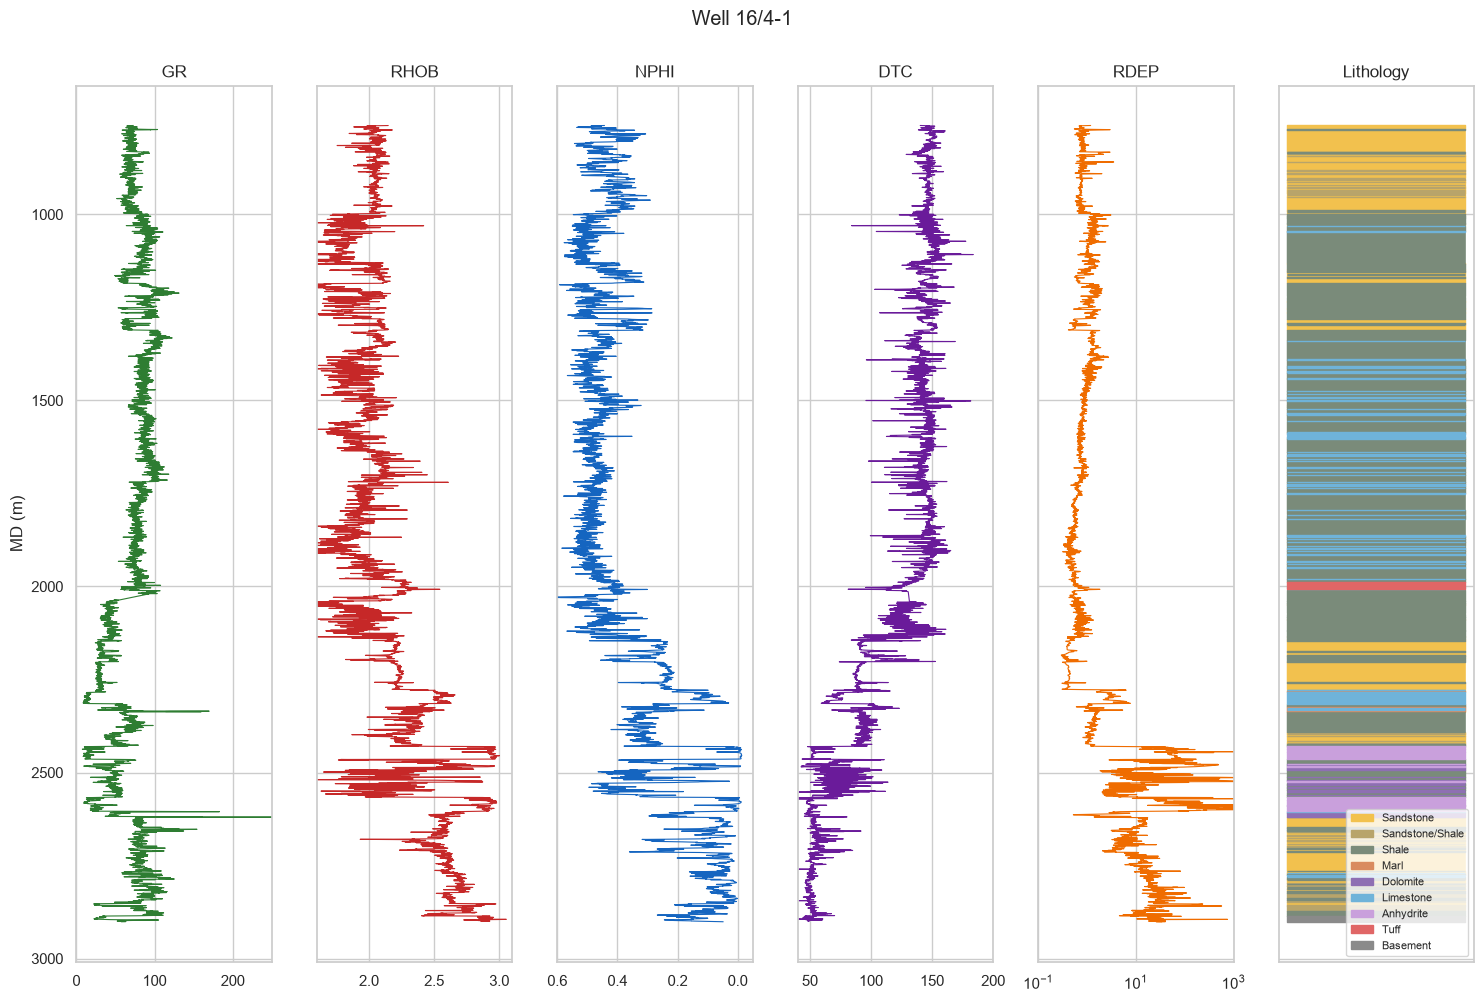

In [14]:
# One well as a geologist sees it: log tracks next to the interpreted lithology.
well_stats = train_clean.groupby(WELL_COL).agg(n_classes=(TARGET_COL, "nunique"), n_rows=(TARGET_COL, "size"))
coverage = train_clean[["GR", "RHOB", "NPHI", "DTC", "RDEP"]].notna().groupby(train_clean[WELL_COL]).mean().min(axis=1)
well_name = (well_stats.join(coverage.rename("min_coverage")).query("min_coverage > 0.9")
             .sort_values("n_classes", ascending=False).index[0])
w = train_clean[train_clean[WELL_COL] == well_name]
depth, cls = w[DEPTH_COL].to_numpy(), w[TARGET_COL].map(CODE_TO_CLASS).to_numpy()

fig, axes = plt.subplots(1, 6, figsize=(15, 10), sharey=True)
specs = [("GR", "#2e7d32", (0, 250), False), ("RHOB", "#c62828", (1.6, 3.1), False),
         ("NPHI", "#1565c0", (0.6, -0.05), False), ("DTC", "#6a1b9a", (40, 200), False),
         ("RDEP", "#ef6c00", (0.1, 1000), True)]
for ax, (col, color, lim, logx) in zip(axes[:5], specs):
    ax.plot(w[col], depth, color=color, lw=0.8)
    if logx:
        ax.set_xscale("log")
    ax.set_xlim(lim); ax.set_title(col)
for k in range(N_CLASSES):
    present = cls == k
    if present.any():
        axes[5].fill_betweenx(depth, 0, 1, where=present, color=CLASS_COLORS[k], step="mid", label=CLASS_NAMES[k])
axes[5].set_xticks([]); axes[5].set_title("Lithology"); axes[5].legend(fontsize=8, loc="lower right")
axes[0].invert_yaxis(); axes[0].set_ylabel("MD (m)")
plt.suptitle(f"Well {well_name}", y=1.0); plt.tight_layout(); plt.show()

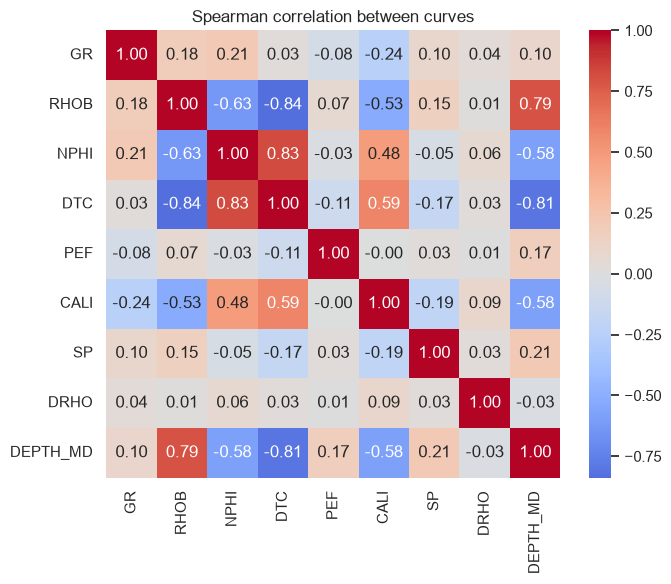

In [15]:
corr_cols = ["GR", "RHOB", "NPHI", "DTC", "PEF", "CALI", "SP", "DRHO", "DEPTH_MD"]
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(train_clean[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Spearman correlation between curves")
plt.tight_layout(); plt.show()

## 6. Feature engineering
Implemented in `lithology/features.py` so that training and the API use identical code. Everything is computed **inside one well**:

- `LOG_*` - log10 of resistivities and rate of penetration (heavy right tails).
- `PHID`, `ND_SEP` - density porosity and neutron-density separation (the classic gas / sandstone / shale cross-over indicator).
- `GR_NORM` - gamma ray scaled by the well's own 5th-95th percentile (removes tool / well calibration offsets).
- Rolling mean / std of GR, RHOB, NPHI, DTC over 15 and 61 samples (~2.3 m and ~9.3 m) - bed context - plus 10-sample gradients of GR and RHOB.

Thinning to every k-th sample happens **after** the rolling features are computed.

In [16]:
KEEP = [WELL_COL, DEPTH_COL, TARGET_COL, CONFIDENCE_COL, "GROUP", "X_LOC", "Y_LOC"]
FEATURES_A, FEATURES_B = FEATURE_SETS["A_logs"], FEATURE_SETS["B_logs_depth"]


def build_frame(df_raw: pd.DataFrame) -> pd.DataFrame:
    """clean -> engineer features -> encode target -> float32."""
    frame = add_features(clean_logs(df_raw))
    cols = [c for c in KEEP if c in frame.columns] + FEATURES_A
    frame = frame[cols].copy()
    frame["y"] = frame[TARGET_COL].map(CODE_TO_CLASS)
    assert frame["y"].notna().all(), "unknown lithology code"
    frame["y"] = frame["y"].astype(int)
    float_cols = frame.select_dtypes("float64").columns
    frame[float_cols] = frame[float_cols].astype("float32")
    return frame


def thin(frame: pd.DataFrame, stride: int) -> pd.DataFrame:
    """Keep every `stride`-th depth sample of every well (frame must be sorted by well, depth)."""
    return frame[frame.groupby(WELL_COL).cumcount() % stride == 0]


t0 = time.time()
train_feat = build_frame(train_raw)
hidden_feat = build_frame(hidden)
lb_feat = build_frame(leaderboard)
print(f"features built in {time.time() - t0:.1f}s | train {train_feat.shape} | {len(FEATURES_A)} log features (+ depth for set B)")
display(train_feat[FEATURES_A].isna().mean().sort_values(ascending=False).head(10).round(3).rename("share missing").to_frame())

features built in 5.9s | train (1170511, 42) | 34 log features (+ depth for set B)


,share missing
LOG_ROP,0.543
LOG_RSHA,0.461
PEF,0.426
BS,0.417
ND_SEP,0.358
NPHI,0.346
NPHI_MEAN15,0.345
NPHI_STD15,0.345
NPHI_STD61,0.343
NPHI_MEAN61,0.343


## 7. Validation design and metric
- **Splitter:** `StratifiedGroupKFold` with the well name as the group: no well is ever in both train and validation, and rare classes are spread across folds as evenly as the groups allow.
- **Primary metric:** the competition penalty score (higher / closer to 0 is better). It punishes confusing, say, sandstone with halite far more than shale with a sandstone/shale mix.
- **Dev set:** training wells thinned to every `STRIDE_DEV`-th sample.

In [17]:
A = load_penalty_matrix(RAW / "penalty_matrix.npy")
penalty_scorer = make_penalty_scorer(A)
SCORING = {
    "penalty": penalty_scorer,
    "macro_f1": make_scorer(f1_score, average="macro", zero_division=0),
    "balanced_acc": make_scorer(balanced_accuracy_score),
    "accuracy": make_scorer(accuracy_score),
}
cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

dev = thin(train_feat, STRIDE_DEV).reset_index(drop=True)
y_dev, g_dev = dev["y"], dev[WELL_COL].to_numpy()
print(f"dev set: {len(dev):,} rows, {dev[WELL_COL].nunique()} wells")

fold_info = []
for k, (tr, va) in enumerate(cv.split(dev, y_dev, g_dev)):
    fold_info.append({"fold": k, "train_wells": len(set(g_dev[tr])), "val_wells": len(set(g_dev[va])),
                      "val_rows": len(va), "classes_in_val": y_dev.iloc[va].nunique(),
                      "classes_in_train": y_dev.iloc[tr].nunique()})
display(pd.DataFrame(fold_info).set_index("fold"))
assert all(set(g_dev[tr]).isdisjoint(g_dev[va]) for tr, va in cv.split(dev, y_dev, g_dev)), "well leakage!"

dev set: 78,076 rows, 98 wells


,train_wells,val_wells,val_rows,classes_in_val,classes_in_train
fold,,,,,
0,77,21,16231,11,12
1,79,19,15563,10,12
2,78,20,16346,11,12
3,77,21,15951,10,12
4,81,17,13985,11,11


## 8. Feature importance and feature-set ablation
**Ablation** - which groups of features earn their place? All four LightGBM runs share the same folds.
- **D** raw curves only; **A** + derived + rolling context; **B** + `DEPTH_MD`; **C** + stratigraphic group and well coordinates (information a user may not have for a new well - shown for reference, not deployed).

In [18]:
def make_lgbm(**overrides) -> lgb.LGBMClassifier:
    params = dict(objective="multiclass", n_estimators=200, learning_rate=0.1, num_leaves=31,
                  random_state=SEED, n_jobs=-1, verbose=-1)
    params.update(overrides)
    return lgb.LGBMClassifier(**params)


feature_sets = {
    "D: raw curves only": RAW_FEATURE_LOGS + LOG10_FEATURES,
    "A: + derived + rolling context": FEATURES_A,
    "B: A + depth": FEATURES_B,
}
ablation_X = {name: dev[cols] for name, cols in feature_sets.items()}
x_c = dev[FEATURES_B + ["GROUP", "X_LOC", "Y_LOC"]].copy()
x_c["GROUP"] = x_c["GROUP"].astype("category")
ablation_X["C: B + stratigraphic group + X/Y (reference)"] = x_c

rows = []
for name, X_ in ablation_X.items():
    res = cross_validate(make_lgbm(n_estimators=ABLATION_TREES), X_, y_dev, groups=g_dev, cv=cv,
                         scoring={k: SCORING[k] for k in ("penalty", "macro_f1")}, n_jobs=1)
    rows.append({"feature set": name, "n_features": X_.shape[1],
                 "penalty": res["test_penalty"].mean(), "penalty_std": res["test_penalty"].std(),
                 "macro_f1": res["test_macro_f1"].mean()})
ablation = pd.DataFrame(rows).set_index("feature set")
display(ablation.round(4))

,n_features,penalty,penalty_std,macro_f1
feature set,,,,
D: raw curves only,13,-1.1776,0.0781,0.2066
A: + derived + rolling context,34,-1.0951,0.1340,0.2286
B: A + depth,35,-1.0195,0.0200,0.2487
C: B + stratigraphic group + X/Y (reference),38,-1.1501,0.0803,0.2282


In [19]:
# Deployable choice: only sets A and B need nothing but logs (+ depth). Pick the better one.
score_a = ablation.loc["A: + derived + rolling context", "penalty"]
score_b = ablation.loc["B: A + depth", "penalty"]
FEATURE_SET_NAME, FEATURES = ("B_logs_depth", FEATURES_B) if score_b >= score_a else ("A_logs", FEATURES_A)
print("Chosen feature set:", FEATURE_SET_NAME, f"({len(FEATURES)} features)")

Chosen feature set: B_logs_depth (35 features)


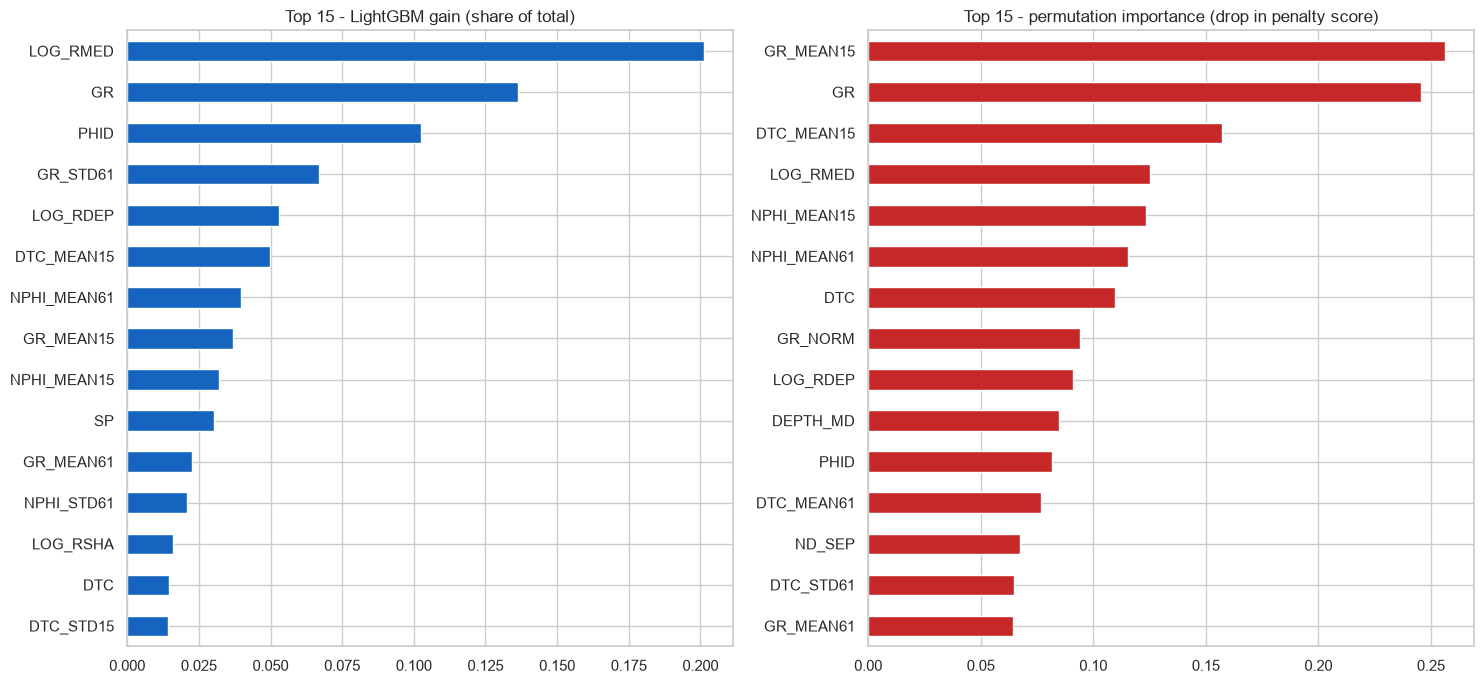

In [20]:
# Feature importance on a held-out fold of wells: LightGBM gain vs permutation importance.
tr_idx, va_idx = next(cv.split(dev, y_dev, g_dev))
imp_model = make_lgbm(n_estimators=ABLATION_TREES).fit(dev.loc[tr_idx, FEATURES], y_dev.iloc[tr_idx])
gain = pd.Series(imp_model.booster_.feature_importance("gain"), index=FEATURES)
gain = (gain / gain.sum()).sort_values(ascending=False)

val_sample = dev.iloc[va_idx].sample(min(15_000, len(va_idx)), random_state=SEED)
perm = permutation_importance(imp_model, val_sample[FEATURES], val_sample["y"], scoring=penalty_scorer,
                              n_repeats=3, random_state=SEED, n_jobs=1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
gain.head(15)[::-1].plot.barh(ax=axes[0], color="#1565c0"); axes[0].set_title("Top 15 - LightGBM gain (share of total)")
perm_imp.head(15)[::-1].plot.barh(ax=axes[1], color="#c62828"); axes[1].set_title("Top 15 - permutation importance (drop in penalty score)")
plt.tight_layout(); plt.show()

**How to read this.** Gain shows which features the trees *used*; permutation importance shows which ones the model *needs* on unseen wells. Features that rank high in both are the real signal.

## 9. Model comparison (default hyper-parameters)
One linear model (multinomial logistic regression) and two tree-based models, plus a majority-class baseline. Linear and random-forest models get median imputation with missing-indicator columns; the linear model also gets a quantile transform so heavy-tailed curves do not dominate.

In [21]:
def make_models() -> dict:
    impute = lambda: SimpleImputer(strategy="median", add_indicator=True)
    return {
        "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": Pipeline([
            ("impute", impute()),
            ("scale", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED)),
            ("clf", LogisticRegression(max_iter=200, C=1.0)),
        ]),
        "Random Forest": Pipeline([
            ("impute", impute()),
            ("clf", RandomForestClassifier(n_estimators=RF_TREES, min_samples_leaf=5, n_jobs=-1, random_state=SEED)),
        ]),
        "LightGBM": make_lgbm(),
    }


Dummy (most frequent)    penalty -1.1566
Logistic Regression      penalty -0.7841
Random Forest            penalty -0.7529
LightGBM                 penalty -1.0373


,penalty,macro_f1,balanced_acc,accuracy,penalty_std,fit_s
model,,,,,,
Dummy (most frequent),-1.1566,0.0720,0.0945,0.6144,0.0664,0.0173
Logistic Regression,-0.7841,0.3235,0.3321,0.7077,0.0464,7.9212
Random Forest,-0.7529,0.3622,0.3307,0.7183,0.0750,8.6508
LightGBM,-1.0373,0.2178,0.2579,0.6226,0.0243,10.4552


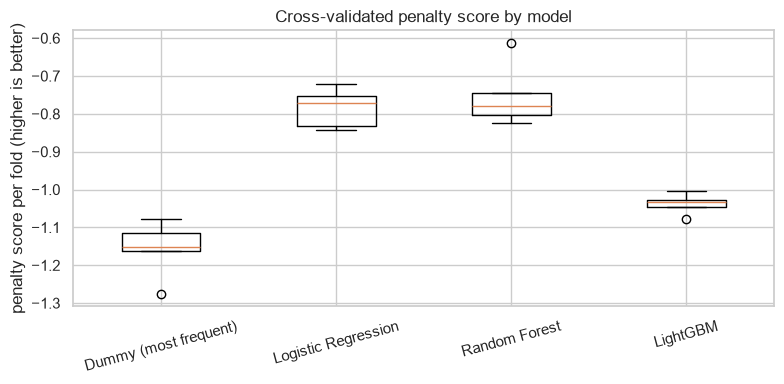

In [22]:
X_dev = dev[FEATURES]
baseline_rows, fold_scores = [], {}
for name, model in make_models().items():
    res = cross_validate(model, X_dev, y_dev, groups=g_dev, cv=cv, scoring=SCORING, n_jobs=1)
    fold_scores[name] = res["test_penalty"]
    baseline_rows.append({"model": name, **{m: res[f"test_{m}"].mean() for m in SCORING},
                          "penalty_std": res["test_penalty"].std(), "fit_s": res["fit_time"].mean()})
    print(f"{name:24s} penalty {baseline_rows[-1]['penalty']:.4f}")
baseline = pd.DataFrame(baseline_rows).set_index("model")
display(baseline.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(list(fold_scores.values()), tick_labels=list(fold_scores.keys()))
ax.set_ylabel("penalty score per fold (higher is better)"); ax.set_title("Cross-validated penalty score by model")
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

## 10. Hyper-parameter tuning
Randomised search for each model family, scored with the penalty score on the **same well-grouped folds**. `class_weight` is part of the search space: balancing helps rare classes but may hurt the penalty score, so we let the metric decide. Search ranges are deliberately modest (widen them for better result but for longer time).

In [23]:
searches = {}

def run_search(name, estimator, space, n_iter):
    t0 = time.time()
    search = RandomizedSearchCV(estimator, space, n_iter=n_iter, scoring=penalty_scorer, cv=cv,
                                random_state=SEED, n_jobs=1, refit=True, error_score="raise")
    search.fit(X_dev, y_dev, groups=g_dev)
    searches[name] = search
    print(f"{name:20s} best CV penalty {search.best_score_:.4f} | {n_iter} candidates | {time.time() - t0:.0f}s")


models = make_models()
run_search("Logistic Regression", models["Logistic Regression"],
           {"clf__C": loguniform(0.01, 30), "clf__class_weight": [None, "balanced"]}, N_ITER_LR)
run_search("Random Forest", models["Random Forest"],
           {"clf__n_estimators": [100, 200, 300], "clf__max_depth": [None, 12, 20],
            "clf__min_samples_leaf": [1, 5, 20], "clf__max_features": ["sqrt", 0.3]}, N_ITER_RF)
run_search("LightGBM", make_lgbm(subsample_freq=1),
           {"n_estimators": [150, 300, 500], "learning_rate": loguniform(0.03, 0.2),
            "num_leaves": [15, 31, 63, 127], "min_child_samples": [20, 50, 100, 200],
            "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.8, 1.0],
            "reg_lambda": [0.0, 1.0, 10.0], "class_weight": [None, "balanced"]}, N_ITER_LGBM)

Logistic Regression  best CV penalty -0.7792 | 4 candidates | 172s
Random Forest        best CV penalty -0.7448 | 6 candidates | 432s
LightGBM             best CV penalty -0.7131 | 12 candidates | 880s


In [24]:
tuning = pd.DataFrame({
    "default CV penalty": baseline.loc[list(searches), "penalty"],
    "tuned CV penalty": {n: s.best_score_ for n, s in searches.items()},
})
tuning["gain"] = tuning["tuned CV penalty"] - tuning["default CV penalty"]
display(tuning.round(4))
for name, s in searches.items():
    print(f"\n{name}: {s.best_params_}")

top = (pd.DataFrame(searches["LightGBM"].cv_results_)
       .sort_values("rank_test_score")[["mean_test_score", "std_test_score", "mean_fit_time", "params"]].head(5))
display(top)

,default CV penalty,tuned CV penalty,gain
Logistic Regression,-0.7841,-0.7792,0.0049
Random Forest,-0.7529,-0.7448,0.0081
LightGBM,-1.0373,-0.7131,0.3241



Logistic Regression: {'clf__C': np.float64(0.20059560245279648), 'clf__class_weight': None}

Random Forest: {'clf__n_estimators': 100, 'clf__min_samples_leaf': 5, 'clf__max_features': 0.3, 'clf__max_depth': None}

LightGBM: {'class_weight': None, 'colsample_bytree': 0.8, 'learning_rate': np.float64(0.03277702274869302), 'min_child_samples': 200, 'n_estimators': 500, 'num_leaves': 31, 'reg_lambda': 1.0, 'subsample': 1.0}


,mean_test_score,std_test_score,mean_fit_time,params
4,-0.713138,0.058428,19.289898,"{'class_weight': None, 'colsample_bytree': 0.8..."
6,-0.722853,0.064174,10.656168,"{'class_weight': None, 'colsample_bytree': 0.5..."
0,-0.724656,0.074627,3.944279,"{'class_weight': None, 'colsample_bytree': 0.5..."
1,-0.726610,0.067709,9.873237,"{'class_weight': None, 'colsample_bytree': 1.0..."
11,-0.734995,0.058194,5.335274,"{'class_weight': None, 'colsample_bytree': 0.5..."


## 11. Final model on blind wells
The winner by tuned cross-validated penalty score is refit on a denser training set (`STRIDE_FINAL`) and evaluated **once** on the 10 hidden-test wells and the 10 leaderboard wells, none of which were seen in training or tuning.

In [25]:
best_name = max(searches, key=lambda n: searches[n].best_score_)
print("Selected model:", best_name)
train_final = thin(train_feat, STRIDE_FINAL)
t0 = time.time()
final_model = clone(searches[best_name].best_estimator_).fit(train_final[FEATURES], train_final["y"])
print(f"final fit on {len(train_final):,} rows in {time.time() - t0:.0f}s")


def evaluate(model, frame):
    pred = model.predict(frame[FEATURES])
    y_true = frame["y"].to_numpy()
    return pred, {
        "penalty": penalty_score(y_true, pred, A),
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "balanced_acc": balanced_accuracy_score(y_true, pred),
        "accuracy": accuracy_score(y_true, pred),
    }


pred_hidden, m_hidden = evaluate(final_model, hidden_feat)
pred_lb, m_lb = evaluate(final_model, lb_feat)
shale = CODE_TO_CLASS[65000]
m_dummy = {"penalty": penalty_score(hidden_feat["y"], np.full(len(hidden_feat), shale), A)}
final_table = pd.DataFrame({"hidden_test (10 wells)": m_hidden, "leaderboard_test (10 wells)": m_lb}).T
display(final_table.round(4))
print("Always-predict-shale baseline penalty on hidden_test:", round(m_dummy["penalty"], 4))

Selected model: LightGBM
final fit on 234,137 rows in 49s


,penalty,macro_f1,balanced_acc,accuracy
hidden_test (10 wells),-0.5782,0.4934,0.5074,0.7717
leaderboard_test (10 wells),-0.5459,0.3662,0.3812,0.7839


Always-predict-shale baseline penalty on hidden_test: -1.308


                 precision    recall  f1-score   support

      Sandstone       0.71      0.68      0.70     14045
Sandstone/Shale       0.51      0.25      0.34     12283
          Shale       0.84      0.93      0.88     71827
           Marl       0.13      0.17      0.14      4396
       Dolomite       0.00      0.00      0.00       287
      Limestone       0.68      0.67      0.67      8374
          Chalk       0.84      0.68      0.75      2905
         Halite       0.99      0.98      0.99      6498
      Anhydrite       0.82      0.32      0.46       597
           Tuff       0.53      0.16      0.24       941
           Coal       0.75      0.75      0.75       244
       Basement       0.00      0.00      0.00         0

       accuracy                           0.77    122397
      macro avg       0.57      0.47      0.49    122397
   weighted avg       0.76      0.77      0.76    122397



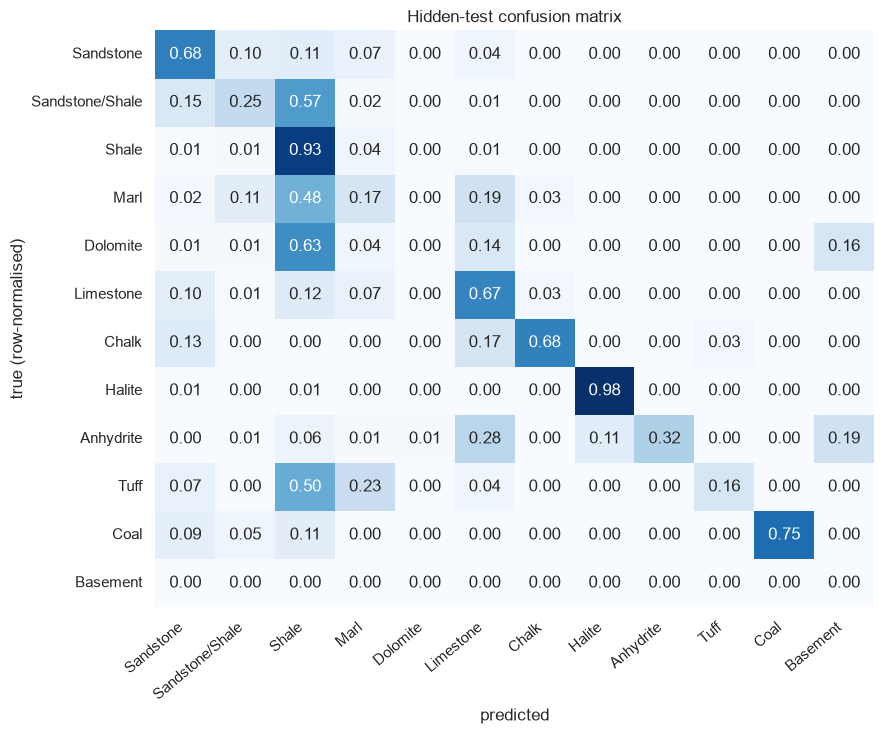

In [26]:
y_h = hidden_feat["y"].to_numpy()
print(classification_report(y_h, pred_hidden, labels=list(range(N_CLASSES)), target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(y_h, pred_hidden, labels=list(range(N_CLASSES)), normalize="true")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax, cbar=False)
ax.set_xlabel("predicted"); ax.set_ylabel("true (row-normalised)"); ax.set_title("Hidden-test confusion matrix")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

,rows,penalty,accuracy
WELL,,,
15/9-23,11063.0,-0.452,0.802
16/2-7,11683.0,-0.610,0.774
16/7-6,10222.0,-0.415,0.809
17/4-1,17271.0,-0.903,0.670
25/10-9,10788.0,-0.673,0.752
31/2-10,9033.0,-0.230,0.918
31/2-21 S,7840.0,-0.528,0.798
34/3-2 S,12216.0,-0.274,0.895
35/11-5,21604.0,-0.684,0.719


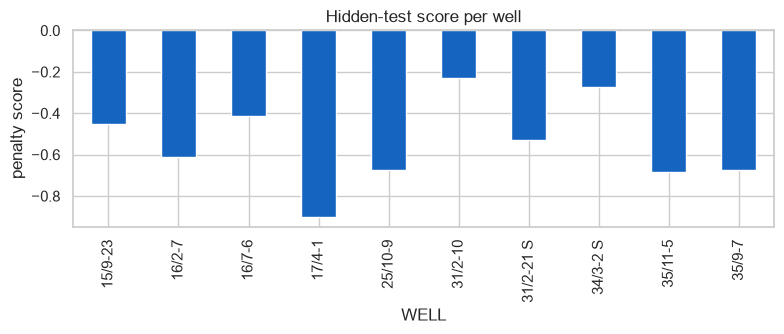

In [27]:
per_well = (hidden_feat.assign(pred=pred_hidden).groupby(WELL_COL)
            .apply(lambda d: pd.Series({"rows": len(d), "penalty": penalty_score(d["y"], d["pred"], A),
                                        "accuracy": accuracy_score(d["y"], d["pred"])}), include_groups=False))
display(per_well.round(3))
fig, ax = plt.subplots(figsize=(8, 3.5))
per_well["penalty"].plot.bar(ax=ax, color="#1565c0"); ax.set_ylabel("penalty score"); ax.set_title("Hidden-test score per well")
plt.tight_layout(); plt.show()

In [28]:
# Rough context only: final scores of the 13 teams that were scored on the hidden set in the 2020
# competition (from the competition repository). Training conditions and tuning data differ.
competition_final = [-0.4690, -0.4792, -0.4954, -0.5045, -0.5084, -0.5087, -0.5091, -0.5171, -0.5173, -0.5221, -0.5256, -0.5263, -0.9441]
rank = 1 + sum(s > m_hidden["penalty"] for s in competition_final)
print(f"This model: {m_hidden['penalty']:.4f} | would sit at position {rank} of {len(competition_final) + 1} next to the 13 competition finalists")

This model: -0.5782 | would sit at position 13 of 14 next to the 13 competition finalists


## 12. Save the selected configuration for `train.py`
The notebook records *what* was chosen (model, feature set, hyper-parameters, metrics). `train.py` reads this file and retrains the final model on all rows, so the training script is reproducible without re-running the search.

In [29]:
def to_jsonable(obj):
    if hasattr(obj, "item"):
        return obj.item()
    return str(obj)


record = {
    "selected_model": best_name,
    "feature_set": FEATURE_SET_NAME,
    "features": FEATURES,
    "best_params": searches[best_name].best_params_,
    "cv_penalty": searches[best_name].best_score_,
    "hidden_test": m_hidden,
    "leaderboard_test": m_lb,
    "settings": {"stride_dev": STRIDE_DEV, "stride_final": STRIDE_FINAL, "n_splits": N_SPLITS, "seed": SEED},
}
(MODELS / "best_config.json").write_text(json.dumps(record, indent=2, default=to_jsonable), encoding="utf-8")
print((MODELS / "best_config.json").read_text(encoding="utf-8")[:1200])

{
  "selected_model": "LightGBM",
  "feature_set": "B_logs_depth",
  "features": [
    "CALI",
    "RHOB",
    "GR",
    "NPHI",
    "PEF",
    "DTC",
    "SP",
    "BS",
    "DRHO",
    "LOG_RSHA",
    "LOG_RMED",
    "LOG_RDEP",
    "LOG_ROP",
    "PHID",
    "ND_SEP",
    "GR_NORM",
    "GR_GRAD",
    "RHOB_GRAD",
    "GR_MEAN15",
    "GR_STD15",
    "RHOB_MEAN15",
    "RHOB_STD15",
    "NPHI_MEAN15",
    "NPHI_STD15",
    "DTC_MEAN15",
    "DTC_STD15",
    "GR_MEAN61",
    "GR_STD61",
    "RHOB_MEAN61",
    "RHOB_STD61",
    "NPHI_MEAN61",
    "NPHI_STD61",
    "DTC_MEAN61",
    "DTC_STD61",
    "DEPTH_MD"
  ],
  "best_params": {
    "class_weight": null,
    "colsample_bytree": 0.8,
    "learning_rate": 0.03277702274869302,
    "min_child_samples": 200,
    "n_estimators": 500,
    "num_leaves": 31,
    "reg_lambda": 1.0,
    "subsample": 1.0
  },
  "cv_penalty": -0.7131377669995096,
  "hidden_test": {
    "penalty": -0.5781544890806147,
    "macro_f1": 0.4934188768345678,
    "ba

## Summary and next steps
- Write the geological interpretation of the top features in README (for example, why neutron-density separation and gamma-ray context matter for sandstone vs shale vs carbonates).
- Fill in the final numbers and the interpretation of the confusion matrix and feature importances in the README.
- Next: `train.py` (reads `models/best_config.json`, trains on all rows, saves the model) and `predict.py` (FastAPI service), then Docker.